In [8]:
import pandas as pd
import numpy as np
from scipy.spatial.transform import Rotation as R

In [9]:
position = pd.read_csv(r"C:\Users\Aini\OneDrive\Documents\Capstone\output.csv")
rotation = pd.read_csv(r"C:\Users\Aini\OneDrive\Documents\Capstone\code\output_notransf.csv")

In [10]:
position

,Unnamed: 0,Hips_Xposition,Hips_Yposition,Hips_Zposition,Spine_Xposition,Spine_Yposition,Spine_Zposition,Spine1_Xposition,Spine1_Yposition,Spine1_Zposition,...,RightUpLeg_Zposition,RightLeg_Xposition,RightLeg_Yposition,RightLeg_Zposition,RightFoot_Xposition,RightFoot_Yposition,RightFoot_Zposition,RightFoot_Nub_Xposition,RightFoot_Nub_Yposition,RightFoot_Nub_Zposition
0,0 days 00:00:00,20.925001,94.647675,23.358198,22.385783,123.151887,25.410623,22.650063,142.560577,24.884577,...,4.654250,18.979635,9.055388,4.736655,19.634225,-75.254968,3.552045,5.508174,-82.918168,-6.797647
1,0 days 00:00:00.008401113,21.054373,94.653931,23.394234,22.517460,123.157840,25.446972,22.792808,142.559736,24.904223,...,4.694404,19.102978,9.061261,4.779018,19.641193,-75.249993,3.555315,5.515140,-82.913193,-6.794375
2,0 days 00:00:00.016802227,21.141069,94.663101,23.365467,22.605420,123.167180,25.423394,22.905498,142.573602,24.874975,...,4.659537,19.168213,9.067327,4.743949,19.634620,-75.241767,3.566812,5.509798,-82.909434,-6.781250
3,0 days 00:00:00.025203340,21.217239,94.664818,23.341904,22.675344,123.168905,25.401323,23.017161,142.583896,24.857886,...,4.645790,19.214295,9.067925,4.702120,19.626080,-75.238428,3.560579,5.494246,-82.906385,-6.777691
4,0 days 00:00:00.033604454,21.252237,94.668900,23.341755,22.707318,123.172617,25.400927,23.093685,142.590916,24.857430,...,4.643199,19.211743,9.072451,4.707033,19.608191,-75.233809,3.579371,5.475521,-82.899296,-6.759587
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62501,0 days 00:08:45.077994433,-39.077332,94.476563,-41.956345,-39.601767,123.067518,-40.915043,-40.388558,142.483850,-41.095492,...,-60.399676,-31.772048,8.500382,-64.262883,-21.651846,-75.218186,-66.248801,-33.780934,-83.219022,-78.668864
62502,0 days 00:08:45.086395546,-38.992867,94.470016,-41.906242,-39.501422,123.060991,-40.855120,-40.286400,142.478139,-41.040164,...,-60.351507,-31.655004,8.500725,-64.233599,-21.663251,-75.227891,-66.285926,-33.793899,-83.228807,-78.704413
62503,0 days 00:08:45.094796660,-38.827045,94.459450,-41.863350,-39.322871,123.050189,-40.803447,-40.096458,142.463802,-41.012664,...,-60.301418,-31.477525,8.497019,-64.197238,-21.719214,-75.248566,-66.344234,-33.869826,-83.245237,-78.745927
62504,0 days 00:08:45.103197773,-38.795631,94.480782,-41.788898,-39.287561,123.071447,-40.724241,-40.031274,142.482189,-40.974194,...,-60.229818,-31.420635,8.514351,-64.137058,-21.735815,-75.235404,-66.372843,-33.888854,-83.228622,-78.774383


In [11]:
rotation

,Unnamed: 0,Hips_Xposition,Hips_Yposition,Hips_Zposition,Hips_Yrotation,Hips_Xrotation,Hips_Zrotation,RightUpLeg_Xposition,RightUpLeg_Yposition,RightUpLeg_Zposition,...,LeftHandPinky2_Zposition,LeftHandPinky2_Yrotation,LeftHandPinky2_Xrotation,LeftHandPinky2_Zrotation,LeftHandPinky3_Xposition,LeftHandPinky3_Yposition,LeftHandPinky3_Zposition,LeftHandPinky3_Yrotation,LeftHandPinky3_Xrotation,LeftHandPinky3_Zrotation
0,0 days 00:00:00,20.925001,94.647675,23.358198,-92.498489,-3.201054,-3.961121,-9.291968,-1.608512,-0.035208,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
1,0 days 00:00:00.008401113,21.054373,94.653931,23.394234,-92.499710,-3.200647,-3.962663,-9.287824,-1.607473,-0.034018,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
2,0 days 00:00:00.016802227,21.141069,94.663101,23.365467,-92.491165,-3.216289,-3.967568,-9.293797,-1.610112,-0.041713,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
3,0 days 00:00:00.025203340,21.217239,94.664818,23.341904,-92.514526,-3.209525,-3.982093,-9.283305,-1.613265,-0.035834,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
4,0 days 00:00:00.033604454,21.252237,94.668900,23.341755,-92.508110,-3.226955,-3.977323,-9.286751,-1.608990,-0.050461,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62501,0 days 00:08:45.077994433,-39.077332,94.476563,-41.956345,-96.954575,0.735775,-2.115421,-9.233133,-1.586134,-0.031478,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
62502,0 days 00:08:45.086395546,-38.992867,94.470016,-41.906242,-97.195671,0.685504,-2.132435,-9.242142,-1.585891,-0.016351,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
62503,0 days 00:08:45.094796660,-38.827045,94.459450,-41.863350,-97.392784,0.644105,-2.150290,-9.242977,-1.584826,-0.021892,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
62504,0 days 00:08:45.103197773,-38.795631,94.480782,-41.788898,-97.587891,0.616376,-2.147043,-9.253761,-1.584450,-0.017432,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0


In [12]:
pos_df = position[['RightArm_Xposition', 'RightArm_Yposition', 'RightArm_Zposition', 'RightForeArm_Xposition', 'RightForeArm_Yposition', 'RightForeArm_Zposition', 'RightHand_Xposition', 'RightHand_Yposition', 'RightHand_Zposition']]


In [13]:
ros_df = rotation[['RightArm_Xrotation', 'RightArm_Yrotation', 'RightArm_Zrotation', 'RightForeArm_Xrotation', 'RightForeArm_Yrotation', 'RightForeArm_Zrotation', 'RightHand_Xrotation', 'RightHand_Yrotation', 'RightHand_Zrotation']]

In [14]:
"""
PIMNet (Physics-infused Neural Network for Human Motion Prediction)
adapted to a 3-segment right-arm chain: RightArm -> RightForeArm -> RightHand.

Pipeline (follows Zhang et al., IEEE RA-L 2022):
  1. Convert Euler rotations -> quaternions (Eq. 15-17 analogue).
  2. Low-fidelity physics model: Newton-Euler inverse dynamics (Eq. 1-8)
        - segment kinematics via Savitzky-Golay differentiation (paper: forward differences)
        - gravity, anthropometric masses / inertias
        - optional hand-ground contact model (Eq. 4-6) + parameter optimisation (Eq. 9)
        - outputs joint torques (+ contact force) per frame  ->  X_p
  3. Physics-infused encoder (LSTM) + temporal decoder (LSTM)  (Eq. 11-13)
  4. L2 loss, Adam, lr 1e-3, 0.9 decay / 10k steps, batch 16   (Eq. 14, Sec. IV-B)
  5. Chronological 80/20 split, metrics: R2 / MSE / MAE for train and val
  6. Ablation: same encoder-decoder WITHOUT physics inputs (paper's "ED" curve)

Usage
-----
    from pimnet_arm import Config, run_pipeline, compare_with_ablation
    cfg = Config(fps=30, pos_scale=0.01, euler_order="ZXY", up_axis=1)
    results = compare_with_ablation(pos_df, ros_df, cfg)
"""
from __future__ import annotations

import copy
import random
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.optimize import minimize
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation as R
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import DataLoader, TensorDataset

# ----------------------------------------------------------------------------
# Column definitions (taken from your snippet)
# ----------------------------------------------------------------------------
JOINTS = ["RightArm", "RightForeArm", "RightHand"]
POS_COLS = [f"{j}_{a}position" for j in JOINTS for a in "XYZ"]
ROT_COLS = [f"{j}_{a}rotation" for j in JOINTS for a in "XYZ"]


# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
@dataclass
class Config:
    # ---- data / physics assumptions (CHECK THESE FOR YOUR DATA) ----
    fps: float = 30.0                 # sampling rate of your mocap data
    pos_scale: float = 0.01           # multiply positions by this to get metres (0.01 if cm)
    euler_order: str = "ZXY"          # BVH default is ZXY; use the order of your export
    degrees: bool = True              # rotations in degrees?
    rot_local: bool = True            # rotations are local (relative to parent), as in BVH
    up_axis: int = 1                  # 0=X, 1=Y, 2=Z is "up" (BVH: Y)
    body_mass: float = 70.0           # kg  (used for Dempster segment masses)
    seg_mass_ratio: tuple = (0.028, 0.016, 0.006)  # upper arm, forearm, hand
    hand_len_ratio: float = 0.7       # hand length as a fraction of forearm length
    seg_radius: float = 0.04          # m, for axial inertia
    sg_window: int = 9                # Savitzky-Golay window (odd)
    sg_poly: int = 3
    floor_height: float | None = None  # up-axis coordinate (m) of floor; None -> no contact
    optimize_contact: bool = True     # Eq. 9 (only runs if floor_height given)

    # ---- model / training ----
    t_in: int = 30                    # past frames fed to the encoder
    horizon: int = 15                 # future frames predicted
    stride: int = 1
    target: str = "both"              # "pos", "rot" (quaternion) or "both"
    hidden: int = 256                 # paper uses 1024; 256 is safer for small data
    layers: int = 1
    dropout: float = 0.0
    batch_size: int = 16
    lr: float = 1e-3
    decay_rate: float = 0.9
    decay_steps: int = 10_000
    epochs: int = 100
    patience: int = 15                # early stopping on val loss
    train_frac: float = 0.8
    seed: int = 42
    device: str = field(default_factory=lambda: "cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------
# 1. Rotations: Euler -> Rotation objects / quaternions
# ----------------------------------------------------------------------------
def euler_to_rotations(ros_arr: np.ndarray, cfg: Config):
    """ros_arr: (T, 9) in column order [X,Y,Z] per joint. Returns list of 3 Rotation objects."""
    T = ros_arr.shape[0]
    ang = ros_arr.reshape(T, 3, 3)
    idx = ["XYZ".index(c) for c in cfg.euler_order.upper()]
    return [R.from_euler(cfg.euler_order.upper(), ang[:, j, idx], degrees=cfg.degrees)
            for j in range(3)]


def quats_continuous(rots) -> np.ndarray:
    """(T, 3*4) quaternion features [x,y,z,w] with sign continuity (q and -q are the same rotation)."""
    out = []
    for r in rots:
        q = r.as_quat().copy()
        for t in range(1, len(q)):
            if np.dot(q[t], q[t - 1]) < 0:
                q[t] = -q[t]
        out.append(q)
    return np.concatenate(out, axis=1)


# ----------------------------------------------------------------------------
# 2. Physics model (low-fidelity Newton-Euler inverse dynamics)
# ----------------------------------------------------------------------------
def _sg(x, cfg: Config, deriv=0):
    w = min(cfg.sg_window, len(x) - (1 - len(x) % 2))
    w = w if w % 2 == 1 else w - 1
    return savgol_filter(x, w, min(cfg.sg_poly, w - 1), deriv=deriv, delta=1.0 / cfg.fps,
                         axis=0, mode="interp")


def _angular_velocity(Rg, dt):
    """World-frame angular velocity via central differences on rotations."""
    T = len(Rg)
    i = np.arange(T)
    nxt, prv = np.minimum(i + 1, T - 1), np.maximum(i - 1, 0)
    rel = Rg[nxt] * Rg[prv].inv()
    return rel.as_rotvec() / ((nxt - prv) * dt)[:, None]


def _inertia_mul(u, w, It, Ia):
    """I_world @ w for a rod with axis u:  I = It (1-uu^T) + Ia uu^T."""
    return It * w + (Ia - It) * u * np.sum(u * w, axis=-1, keepdims=True)


def compute_kinematics(pos_arr: np.ndarray, rots, cfg: Config) -> dict:
    """Segment COM acceleration, angular vel/acc, bone axes, hand-tip velocity."""
    dt = 1.0 / cfg.fps
    T = pos_arr.shape[0]
    P3 = pos_arr.reshape(T, 3, 3) * cfg.pos_scale          # shoulder, elbow, wrist
    tip = P3[:, 2] + cfg.hand_len_ratio * (P3[:, 2] - P3[:, 1])  # hand end-point
    P = np.stack([P3[:, 0], P3[:, 1], P3[:, 2], tip], axis=1)    # (T, 4, 3)
    P = np.stack([_sg(P[:, k], cfg, 0) for k in range(4)], axis=1)

    com = 0.5 * (P[:, :-1] + P[:, 1:])                       # (T, 3 segs, 3)
    a = np.stack([_sg(com[:, s], cfg, 2) for s in range(3)], axis=1)
    v_tip = _sg(P[:, 3], cfg, 1)

    # global segment orientations
    if cfg.rot_local:
        Rg = [rots[0], rots[0] * rots[1], rots[0] * rots[1] * rots[2]]
    else:
        Rg = rots
    omega, alpha = [], []
    for s in range(3):
        w = _sg(_angular_velocity(Rg[s], dt), cfg, 0)
        omega.append(w)
        alpha.append(_sg(w, cfg, 1))

    seg_vec = P[:, 1:] - P[:, :-1]                           # (T, 3, 3)
    L = np.linalg.norm(seg_vec, axis=-1)                     # (T, 3)
    u = seg_vec / (L[..., None] + 1e-9)
    return dict(P=P, com=com, a=a, v_tip=v_tip, omega=np.stack(omega, 1),
                alpha=np.stack(alpha, 1), u=u, L=L, Rg=Rg)


def contact_force(theta, kin, cfg: Config) -> np.ndarray:
    """Eq. (4)-(6): sigmoid-modulated spring-damper normal force + damper friction (hand tip)."""
    T = kin["P"].shape[0]
    if cfg.floor_height is None:
        return np.zeros((T, 3))
    k, cn, ct = theta
    S = lambda x: 0.5 * (1.0 + np.tanh(x))
    n = np.zeros(3)
    n[cfg.up_axis] = 1.0
    d = kin["P"][:, 3, cfg.up_axis] - cfg.floor_height       # distance to surface
    v = kin["v_tip"]
    vn = v @ n
    fn = -k * (d - 1.0) - cn * vn                            # Eq. 5 (as written in the paper)
    ft = -ct * (v - vn[:, None] * n[None])                   # Eq. 6
    gate = (S(-60.0 * d) * S(5.0 * fn))[:, None]
    return gate * (fn[:, None] * n[None] + ft)               # Eq. 4


def newton_euler(kin, f_contact, cfg: Config):
    """
    Recursive Newton-Euler from hand to shoulder (matrix form Eq. 1/7/8 solved per frame).
    Returns joint forces f (T,3,3) and joint torques tau (T,3,3) in the world frame.
    tau[:, s] is the torque the parent exerts on segment s at its proximal joint
    (shoulder, elbow, wrist) -> the "internal torque" tau of Eq. (8).
    """
    T = kin["P"].shape[0]
    g = np.zeros(3)
    g[cfg.up_axis] = -9.81
    P, com, a = kin["P"], kin["com"], kin["a"]
    f = np.zeros((T, 3, 3))
    tau = np.zeros((T, 3, 3))
    f_next = np.zeros((T, 3))
    tau_next = np.zeros((T, 3))
    for s in (2, 1, 0):
        m = cfg.body_mass * cfg.seg_mass_ratio[s]
        L = kin["L"][:, s:s + 1]
        It = m * L ** 2 / 12.0
        Ia = 0.5 * m * cfg.seg_radius ** 2
        u, w, al = kin["u"][:, s], kin["omega"][:, s], kin["alpha"][:, s]
        f_ext = f_contact if s == 2 else np.zeros((T, 3))
        r_prox = P[:, s] - com[:, s]
        r_dist = P[:, s + 1] - com[:, s]

        f[:, s] = m * (a[:, s] - g) + f_next - f_ext
        Iw = _inertia_mul(u, w, It, Ia)
        tau[:, s] = (_inertia_mul(u, al, It, Ia) + np.cross(w, Iw) + tau_next
                     - np.cross(r_prox, f[:, s]) + np.cross(r_dist, f_next)
                     - np.cross(r_dist, f_ext))
        f_next, tau_next = f[:, s], tau[:, s]
    return f, tau


def optimise_contact_params(kin, cfg: Config) -> np.ndarray:
    """Eq. (9): find theta=[k,cn,ct] minimising the root residual force (shoulder joint force)."""
    def cost(theta):
        fc = contact_force(theta, kin, cfg)
        f, _ = newton_euler(kin, fc, cfg)
        return float(np.mean(np.sum(f[:, 0] ** 2, axis=-1)))
    res = minimize(cost, x0=[10.0, 5.0, 5.0], method="L-BFGS-B",
                   bounds=[(1, 20), (0.1, 20), (0.1, 20)])
    return res.x


def physics_features(pos_arr, rots, cfg: Config):
    """Returns X_p (T, 12): 3 joint torques (segment frame) + 1 contact force, each 3-D."""
    kin = compute_kinematics(pos_arr, rots, cfg)
    theta = np.array([10.0, 5.0, 5.0])
    if cfg.floor_height is not None and cfg.optimize_contact:
        theta = optimise_contact_params(kin, cfg)
        print(f"[physics] optimised contact params k={theta[0]:.2f}, cn={theta[1]:.2f}, ct={theta[2]:.2f}")
    elif cfg.floor_height is None:
        print("[physics] floor_height=None -> contact forces set to zero (free-space arm motion).")
    fc = contact_force(theta, kin, cfg)
    _, tau = newton_euler(kin, fc, cfg)
    # express torques in each segment's own frame (muscle torques act in the joint frame)
    tau_loc = np.stack([kin["Rg"][s].inv().apply(tau[:, s]) for s in range(3)], axis=1)
    return np.concatenate([tau_loc.reshape(len(tau_loc), -1), fc], axis=1)


# ----------------------------------------------------------------------------
# 3. Data preparation
# ----------------------------------------------------------------------------
class MinMax11:
    """Per-feature scaling to [-1, 1] (paper normalises features to [-1, 1])."""
    def fit(self, x):
        self.lo, self.hi = x.min(0), x.max(0)
        return self

    def transform(self, x):
        return 2 * (x - self.lo) / (self.hi - self.lo + 1e-8) - 1

    def inverse(self, x):
        return (x + 1) / 2 * (self.hi - self.lo + 1e-8) + self.lo


def make_windows(F_in, F_out, t_in, horizon, stride):
    n = len(F_in) - t_in - horizon + 1
    if n <= 0:
        raise ValueError("Not enough frames for the chosen t_in + horizon.")
    idx = np.arange(0, n, stride)
    X = np.stack([F_in[i:i + t_in] for i in idx]).astype(np.float32)
    Y = np.stack([F_out[i + t_in:i + t_in + horizon] for i in idx]).astype(np.float32)
    return X, Y


def build_features(pos_df, ros_df, cfg: Config, use_physics: bool):
    pos_arr = pos_df[POS_COLS].to_numpy(dtype=float)
    ros_arr = ros_df[ROT_COLS].to_numpy(dtype=float)
    rots = euler_to_rotations(ros_arr, cfg)
    quat = quats_continuous(rots)
    pos_m = pos_arr * cfg.pos_scale
    parts = [pos_m, quat]
    if use_physics:
        parts.append(physics_features(pos_arr, rots, cfg))
    F_in = np.concatenate(parts, axis=1)
    F_out = {"pos": pos_m, "rot": quat, "both": np.concatenate([pos_m, quat], axis=1)}[cfg.target]
    return F_in, F_out


# ----------------------------------------------------------------------------
# 4. Model: physics-infused encoder + temporal decoder
# ----------------------------------------------------------------------------
class PIMNet(nn.Module):
    def __init__(self, d_in, d_out, hidden, layers, horizon, dropout=0.0):
        super().__init__()
        dp = dropout if layers > 1 else 0.0
        self.horizon = horizon
        self.encoder = nn.LSTM(d_in, hidden, layers, batch_first=True, dropout=dp)   # Eq. 11
        self.decoder = nn.LSTM(hidden, hidden, layers, batch_first=True, dropout=dp)  # Eq. 12
        self.out = nn.Linear(hidden, d_out)

    def forward(self, x):                       # x: (B, T_in, d_in)  = [X_i, X_p]
        _, (h, _) = self.encoder(x)
        ctx = h[-1].unsqueeze(1).repeat(1, self.horizon, 1)   # encoder state fed to decoder
        y, _ = self.decoder(ctx)
        return self.out(y)                      # (B, L, d_out)


@torch.no_grad()
def predict(model, X, device, bs=256):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(X[i:i + bs]).to(device)).cpu().numpy())
    return np.concatenate(out)


def train_model(model, Xtr, Ytr, Xva, Yva, cfg: Config):
    dev = cfg.device
    model.to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=cfg.decay_steps, gamma=cfg.decay_rate)
    loss_fn = nn.MSELoss()                                       # l2 loss, Eq. 14
    dl = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(Ytr)),
                    batch_size=cfg.batch_size, shuffle=True)
    best, best_state, bad = np.inf, None, 0
    hist = {"train": [], "val": []}
    for ep in range(1, cfg.epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(dev), yb.to(dev)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            sched.step()
            tot += loss.item() * len(xb)
            n += len(xb)
        va = float(np.mean((predict(model, Xva, dev) - Yva) ** 2))
        hist["train"].append(tot / n)
        hist["val"].append(va)
        if ep == 1 or ep % 5 == 0:
            print(f"epoch {ep:3d} | train mse {tot / n:.5f} | val mse {va:.5f}")
        if va < best - 1e-7:
            best, best_state, bad = va, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= cfg.patience:
                print(f"early stopping at epoch {ep}")
                break
    model.load_state_dict(best_state)
    return model, hist


# ----------------------------------------------------------------------------
# 5. Evaluation
# ----------------------------------------------------------------------------
def regression_metrics(Y_true, Y_pred, scaler: MinMax11) -> dict:
    """Metrics on the ORIGINAL scale (metres / quaternion units); flattened over samples x horizon."""
    d = Y_true.shape[-1]
    yt = scaler.inverse(Y_true.reshape(-1, d))
    yp = scaler.inverse(Y_pred.reshape(-1, d))
    return {"R2": r2_score(yt, yp), "MSE": mean_squared_error(yt, yp),
            "MAE": mean_absolute_error(yt, yp)}


def run_pipeline(pos_df: pd.DataFrame, ros_df: pd.DataFrame, cfg: Config | None = None,
                 use_physics: bool = True) -> dict:
    cfg = cfg or Config()
    set_seed(cfg.seed)
    tag = "PIMNet (physics-infused)" if use_physics else "ED ablation (no physics)"
    print(f"\n===== {tag} | device={cfg.device} =====")

    F_in, F_out = build_features(pos_df, ros_df, cfg, use_physics)

    # chronological 80/20 split on the raw sequence -> no window overlap / leakage
    cut = int(len(F_in) * cfg.train_frac)
    sc_in = MinMax11().fit(F_in[:cut])           # fit on TRAIN only
    sc_out = MinMax11().fit(F_out[:cut])
    A, B = sc_in.transform(F_in), sc_out.transform(F_out)
    Xtr, Ytr = make_windows(A[:cut], B[:cut], cfg.t_in, cfg.horizon, cfg.stride)
    Xva, Yva = make_windows(A[cut:], B[cut:], cfg.t_in, cfg.horizon, cfg.stride)
    print(f"train windows: {len(Xtr)} | val windows: {len(Xva)} | "
          f"input dim: {Xtr.shape[-1]} | output dim: {Ytr.shape[-1]}")

    model = PIMNet(Xtr.shape[-1], Ytr.shape[-1], cfg.hidden, cfg.layers, cfg.horizon, cfg.dropout)
    model, hist = train_model(model, Xtr, Ytr, Xva, Yva, cfg)

    m_tr = regression_metrics(Ytr, predict(model, Xtr, cfg.device), sc_out)
    m_va = regression_metrics(Yva, predict(model, Xva, cfg.device), sc_out)
    print(f"\n{tag}")
    print(f"  TRAIN: R2={m_tr['R2']:.4f}  MSE={m_tr['MSE']:.6f}  MAE={m_tr['MAE']:.6f}")
    print(f"  VAL  : R2={m_va['R2']:.4f}  MSE={m_va['MSE']:.6f}  MAE={m_va['MAE']:.6f}")
    return {"model": model, "history": hist, "train": m_tr, "val": m_va,
            "scalers": (sc_in, sc_out), "cfg": cfg}


def compare_with_ablation(pos_df, ros_df, cfg: Config | None = None) -> pd.DataFrame:
    """Runs PIMNet and the physics-free ED ablation and prints a comparison table."""
    cfg = cfg or Config()
    rows = {}
    for name, flag in [("PIMNet", True), ("ED (no physics)", False)]:
        r = run_pipeline(pos_df, ros_df, cfg, use_physics=flag)
        rows[name] = {"R2_train": r["train"]["R2"], "R2_val": r["val"]["R2"],
                      "MSE_train": r["train"]["MSE"], "MSE_val": r["val"]["MSE"],
                      "MAE_train": r["train"]["MAE"], "MAE_val": r["val"]["MAE"]}
    table = pd.DataFrame(rows).T
    print("\n" + table.to_string(float_format=lambda x: f"{x:.5f}"))
    return table


if __name__ == "__main__":
    # ---- replace with your own data loading ----
    
    cfg = Config(fps=30, pos_scale=0.01, euler_order="XYZ", up_axis=1)
    compare_with_ablation(pos_df, ros_df, cfg)
    raise SystemExit("Edit the __main__ block (or import this module) to load your data.")


===== PIMNet (physics-infused) | device=cpu =====
[physics] floor_height=None -> contact forces set to zero (free-space arm motion).
train windows: 49960 | val windows: 12458 | input dim: 33 | output dim: 21
epoch   1 | train mse 0.00363 | val mse 0.00406
epoch   5 | train mse 0.00047 | val mse 0.00446
epoch  10 | train mse 0.00024 | val mse 0.00488
epoch  15 | train mse 0.00016 | val mse 0.00581
early stopping at epoch 19

PIMNet (physics-infused)
  TRAIN: R2=0.9931  MSE=0.000121  MAE=0.007394
  VAL  : R2=0.9432  MSE=0.000861  MAE=0.017536

===== ED ablation (no physics) | device=cpu =====
train windows: 49960 | val windows: 12458 | input dim: 21 | output dim: 21
epoch   1 | train mse 0.00376 | val mse 0.00381
epoch   5 | train mse 0.00050 | val mse 0.00362
epoch  10 | train mse 0.00027 | val mse 0.00429
epoch  15 | train mse 0.00018 | val mse 0.00529
early stopping at epoch 18

ED ablation (no physics)
  TRAIN: R2=0.9930  MSE=0.000131  MAE=0.007359
  VAL  : R2=0.9463  MSE=0.000855  

SystemExit: Edit the __main__ block (or import this module) to load your data.

C:\Users\Aini\AppData\Roaming\Python\Python314\site-packages\IPython\core\interactiveshell.py:3756: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)



===== PIMNet (physics-infused) | device=cpu =====
[physics] floor_height=None -> contact forces set to zero (free-space arm motion).
train windows: 49960 | val windows: 12458 | input dim: 33 | output dim: 21
epoch   1 | train 0.00134 | val 0.00115 | lr 1.0e-03
epoch   5 | train 0.00077 | val 0.00177 | lr 1.0e-03
epoch  10 | train 0.00057 | val 0.00159 | lr 5.0e-04
epoch  15 | train 0.00050 | val 0.00215 | lr 2.5e-04
early stopping at epoch 17 (best val 0.00113)

PIMNet (physics-infused)
  TRAIN: R2=0.9901  MSE=0.000194  MAE=0.006264
  VAL  : R2=0.9854  MSE=0.000257  MAE=0.007151
  VAL baseline (repeat last frame): R2=0.9878  MSE=0.000210  MAE=0.005297

===== ED ablation (no physics) | device=cpu =====
train windows: 49960 | val windows: 12458 | input dim: 21 | output dim: 21
epoch   1 | train 0.00130 | val 0.00126 | lr 1.0e-03
epoch   5 | train 0.00075 | val 0.00161 | lr 1.0e-03
epoch  10 | train 0.00057 | val 0.00174 | lr 5.0e-04
epoch  15 | train 0.00051 | val 0.00175 | lr 2.5e-04
e

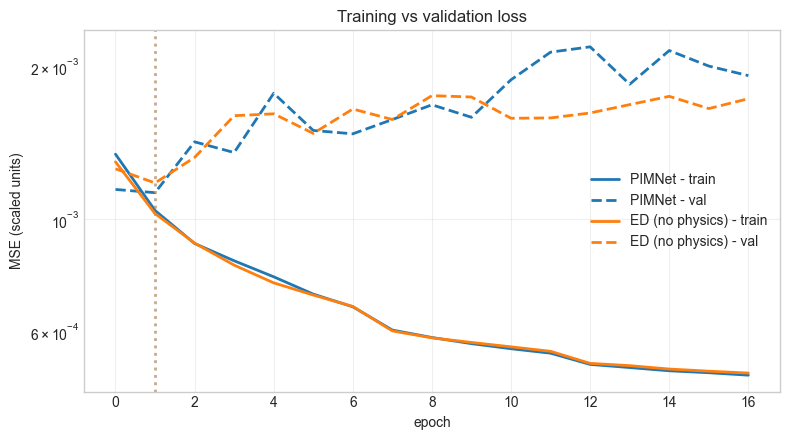

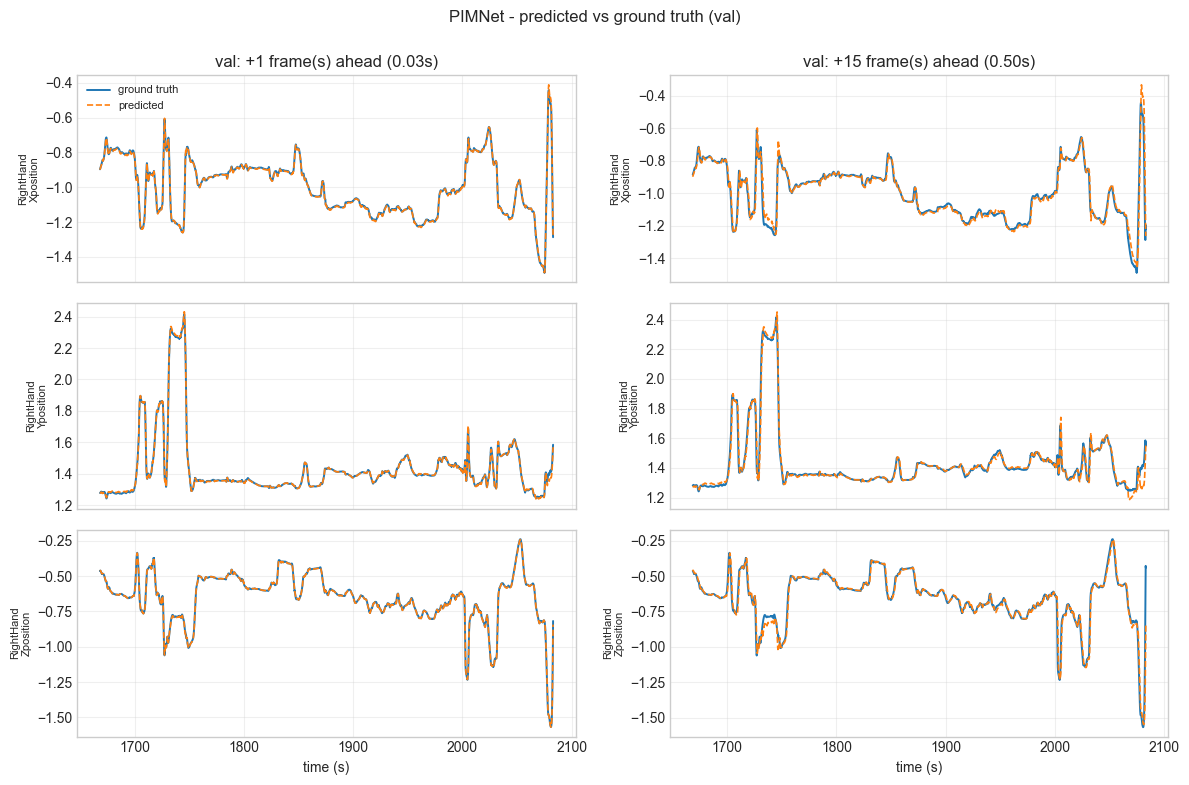

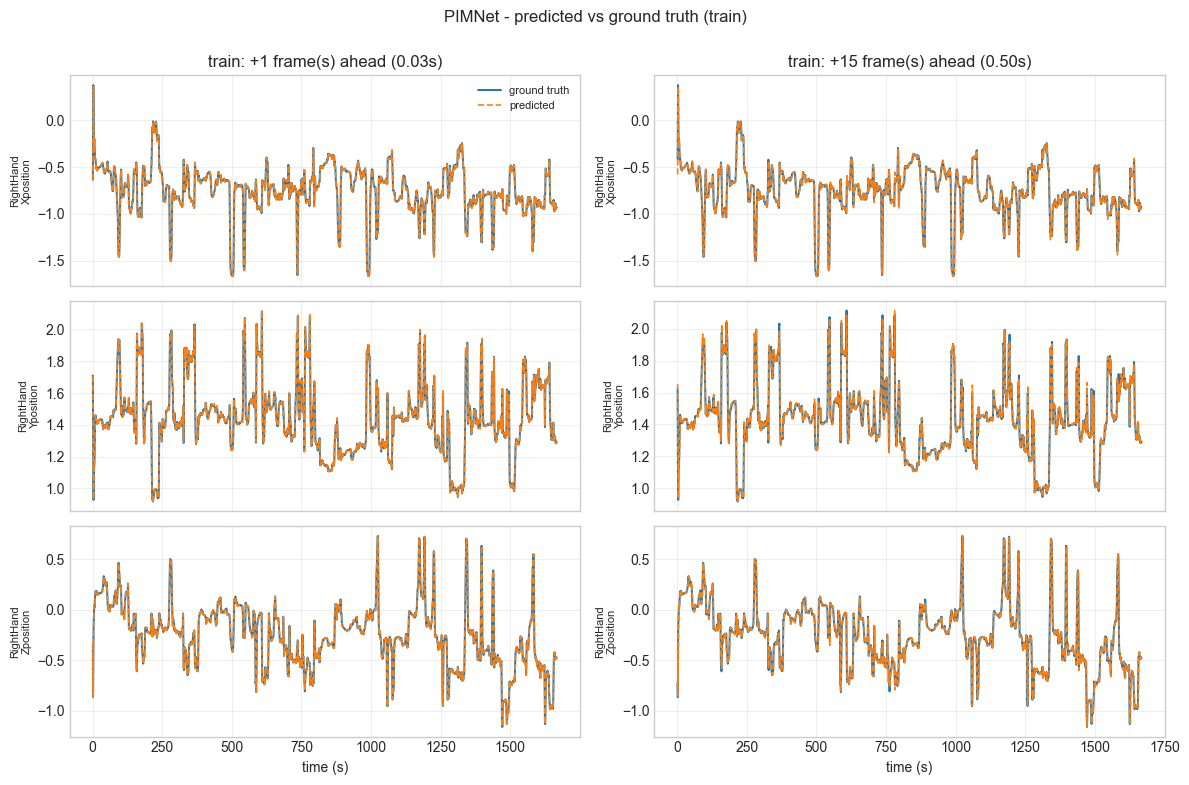

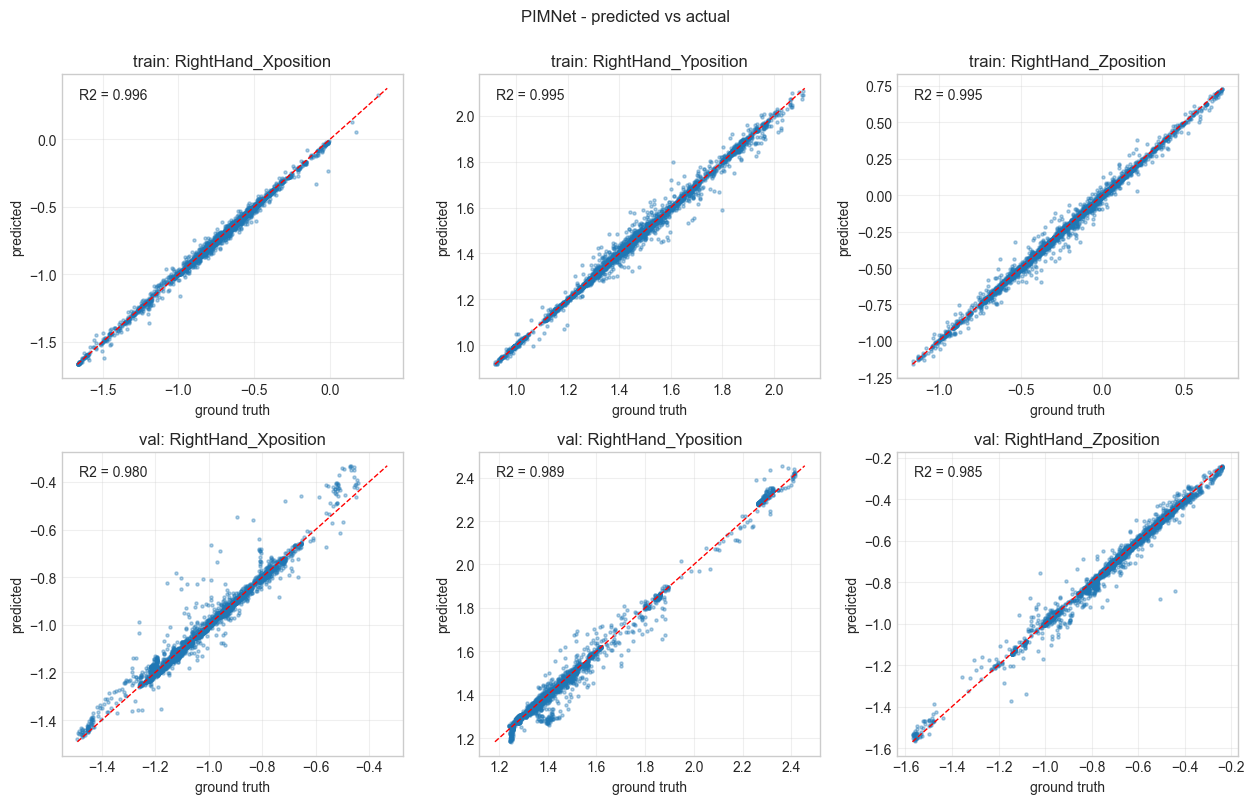

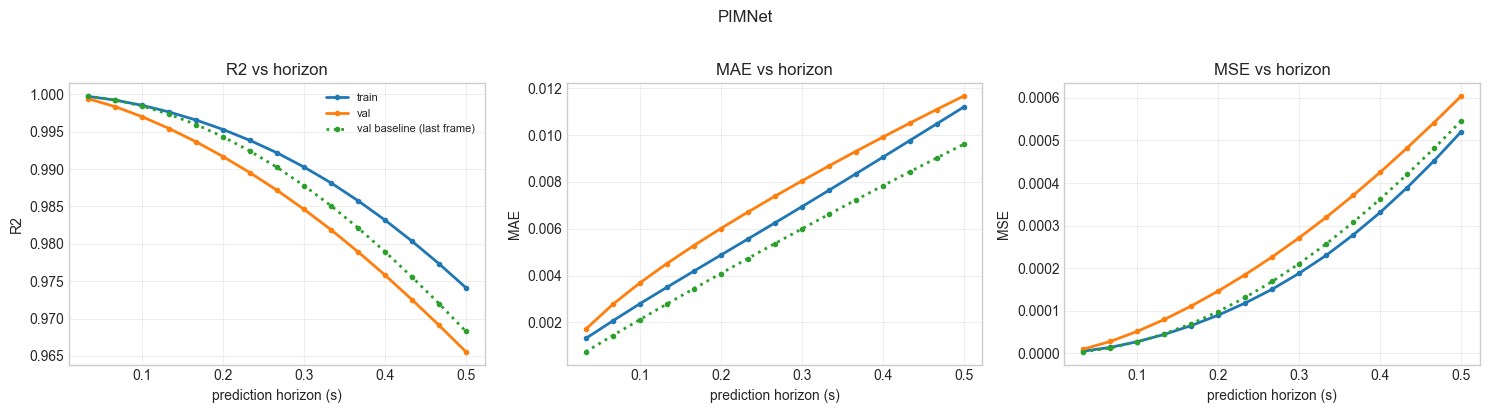

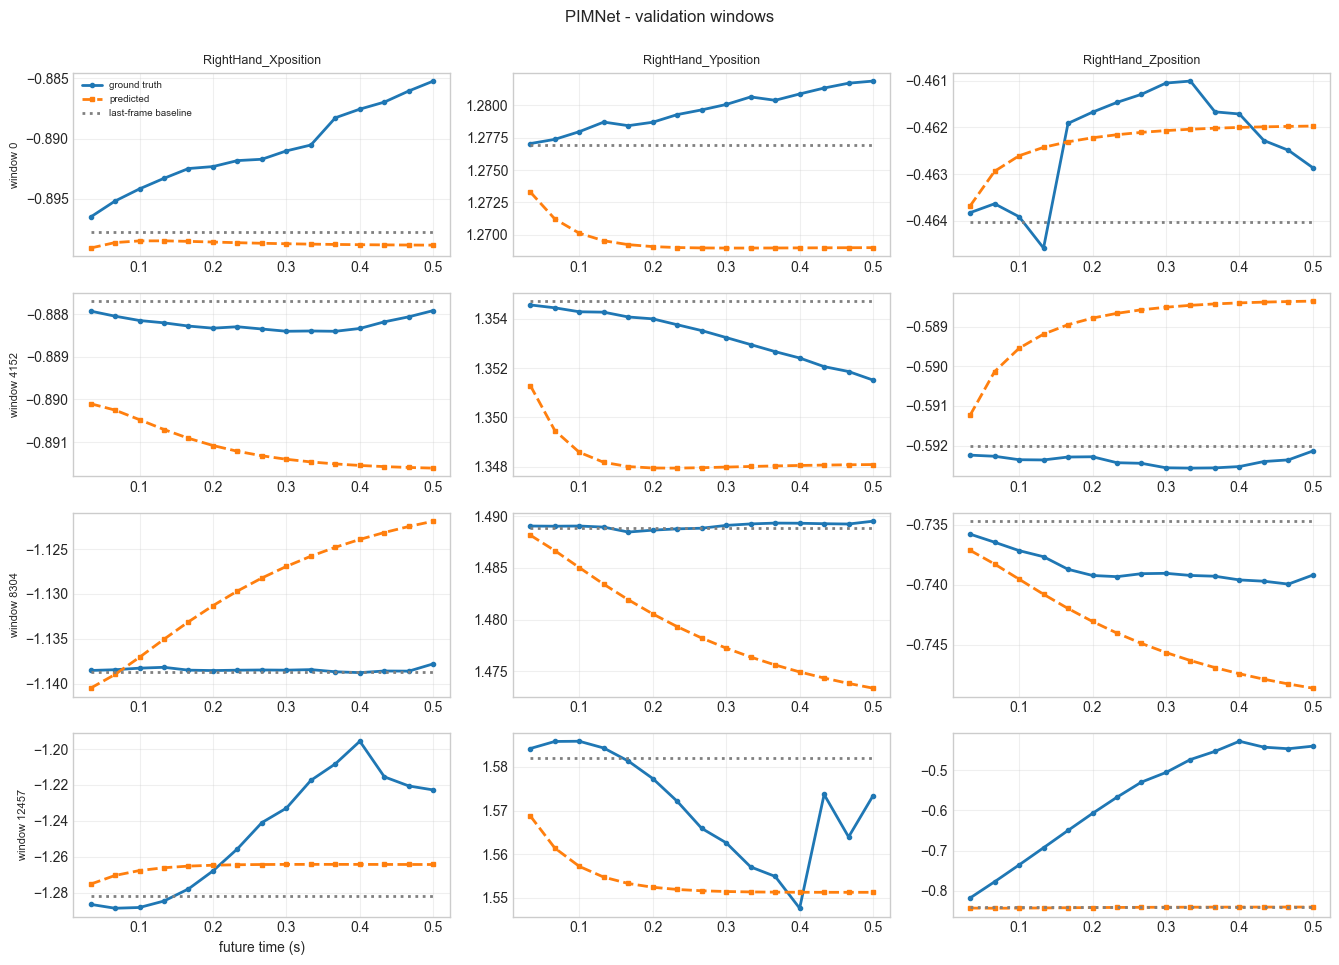

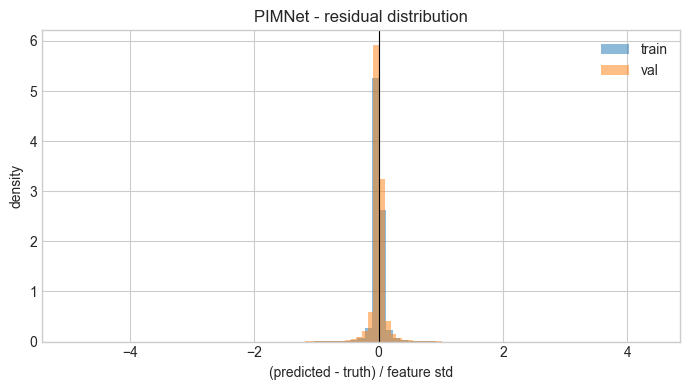

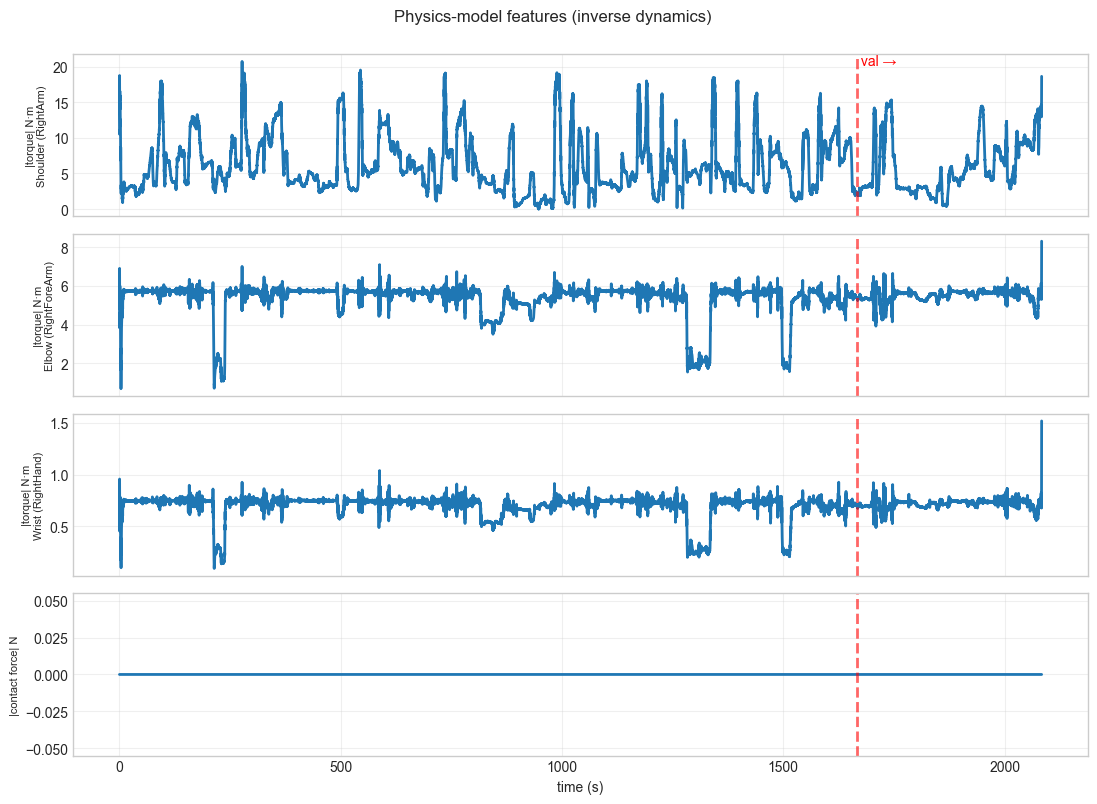

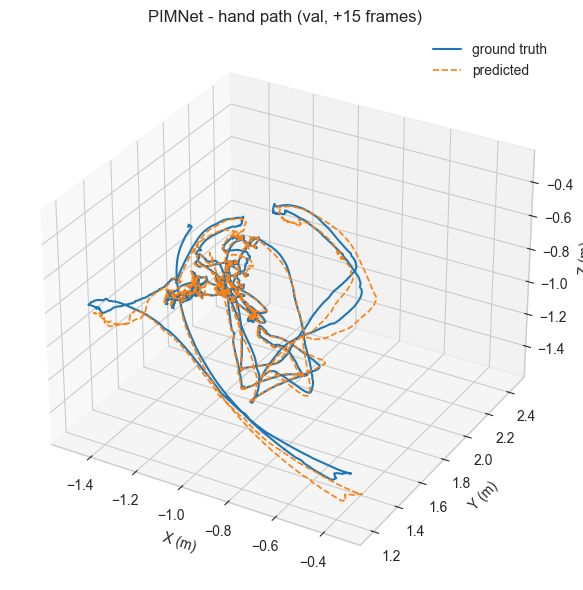

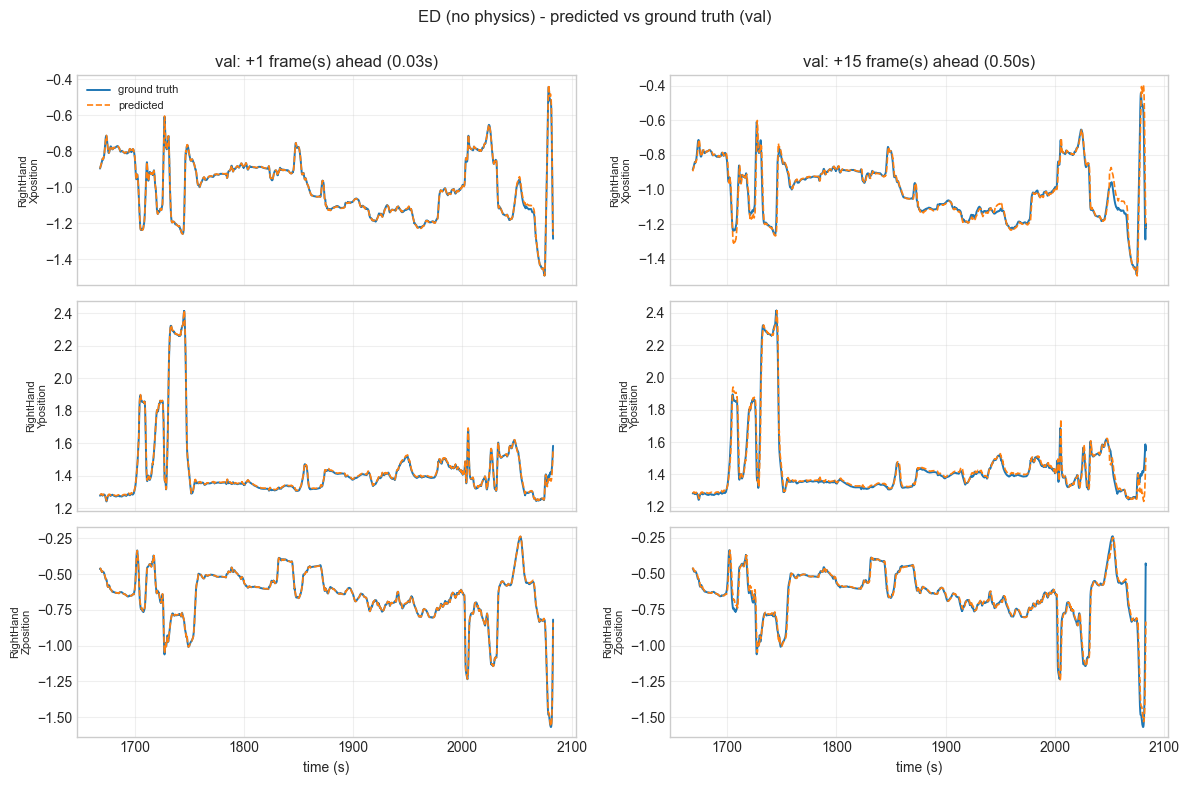

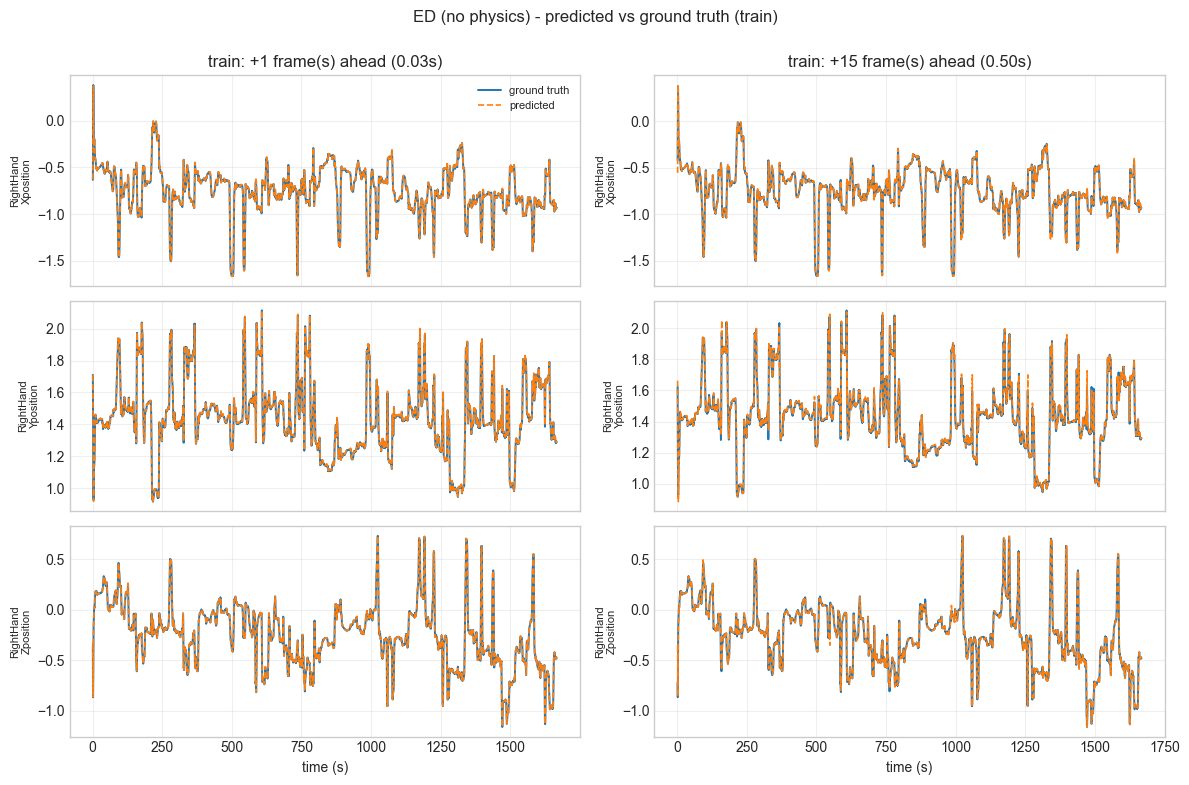

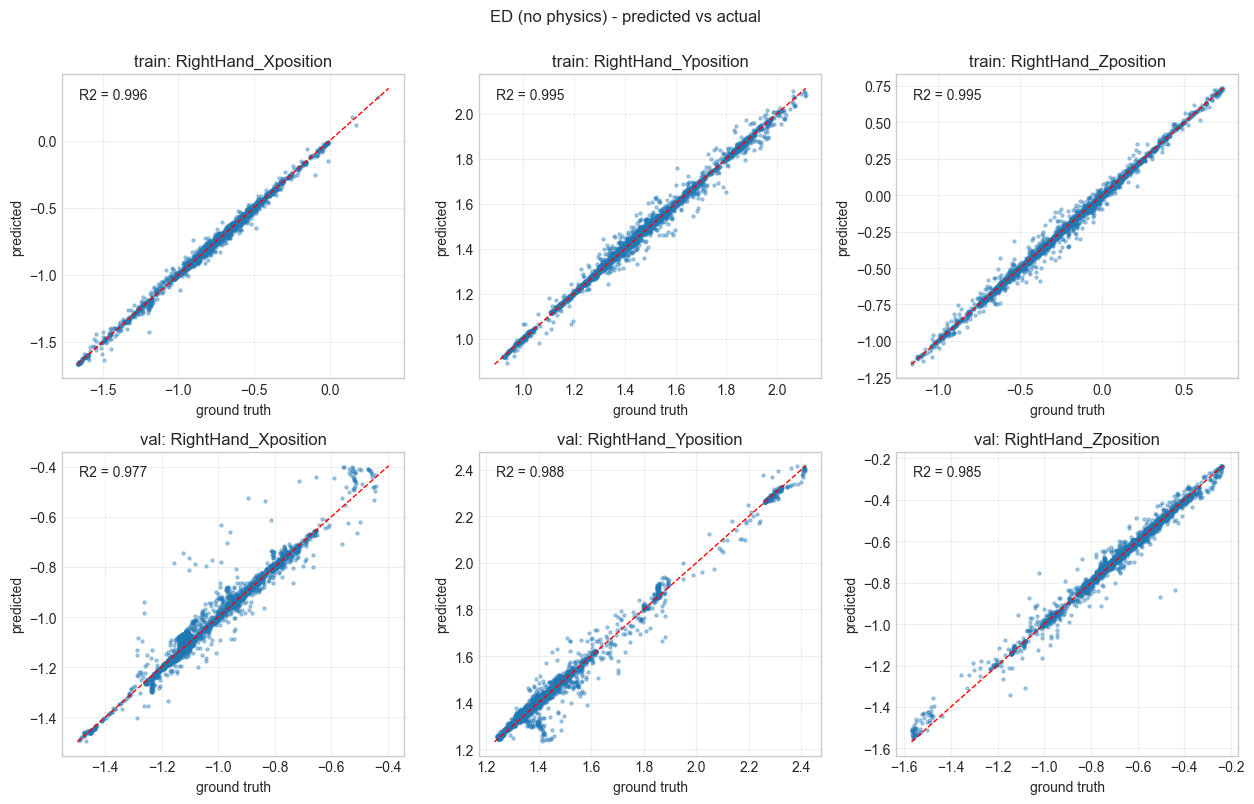

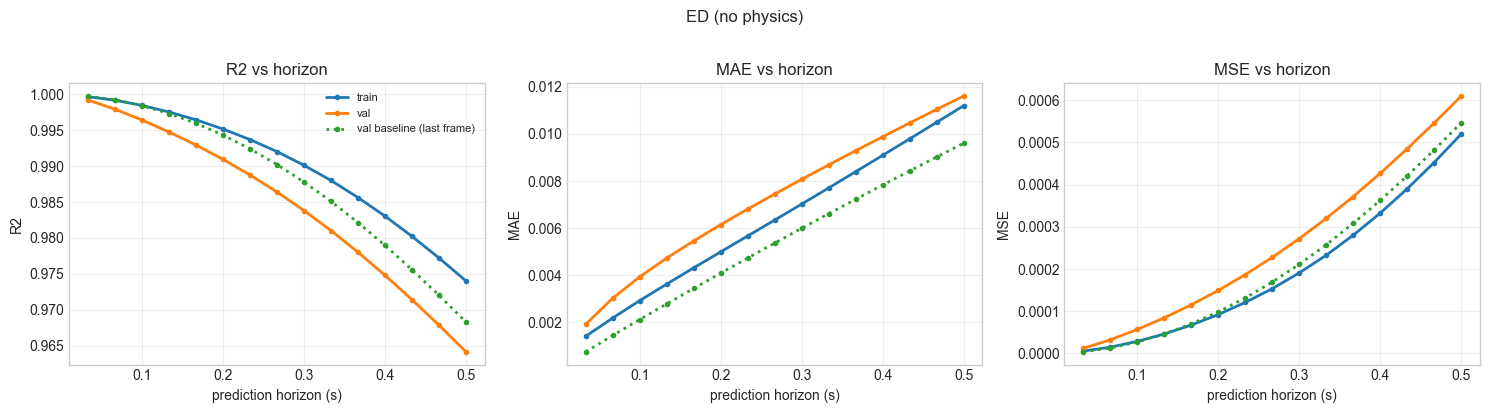

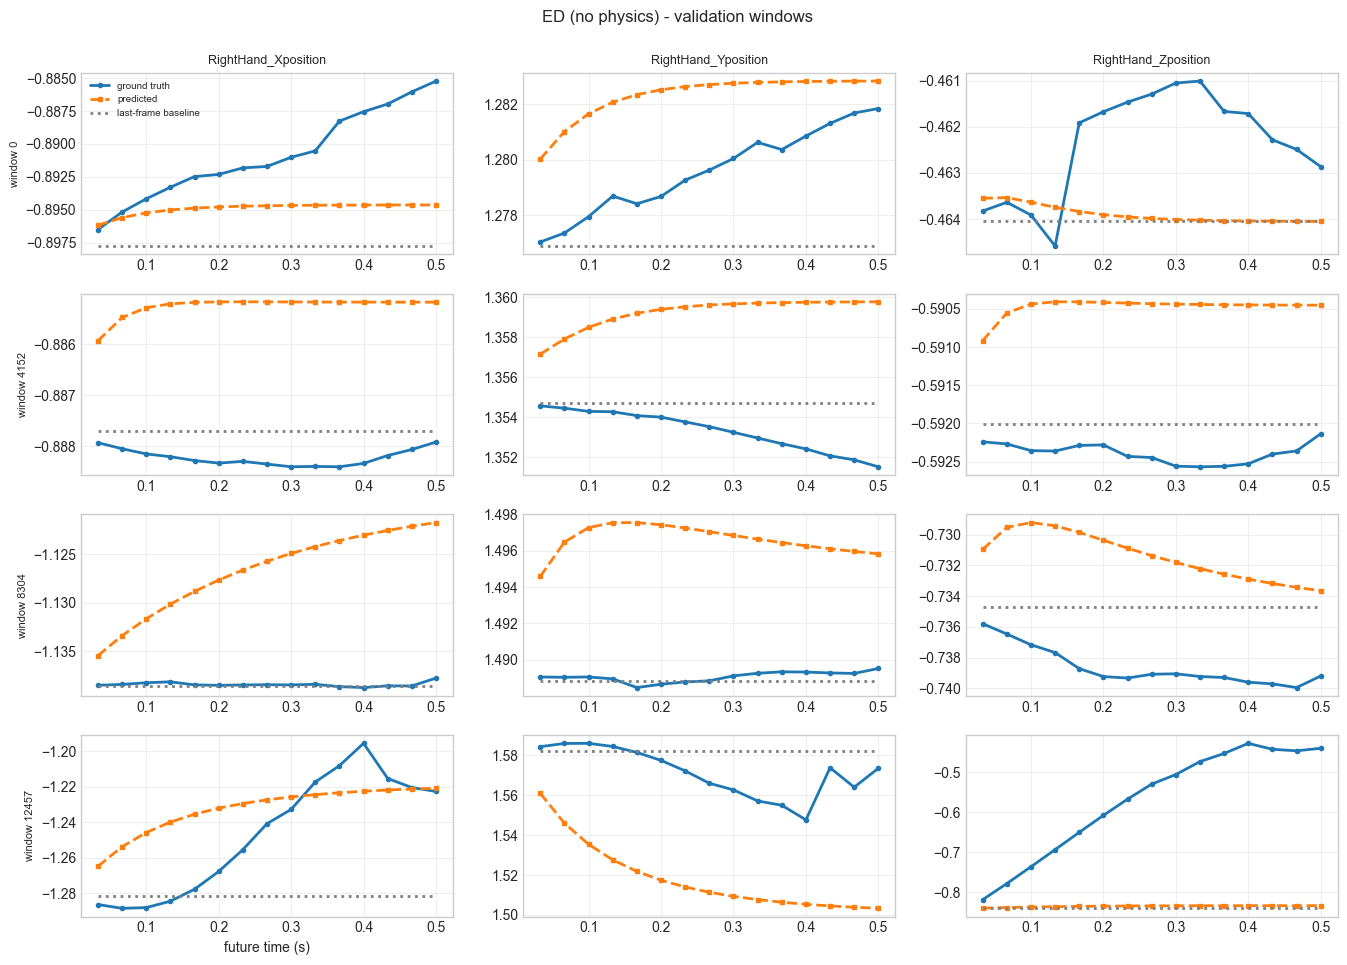

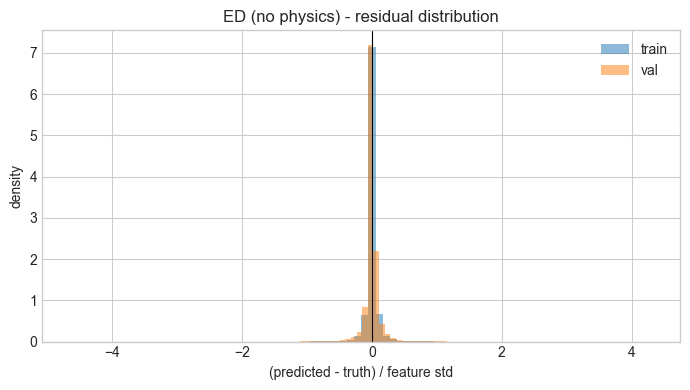

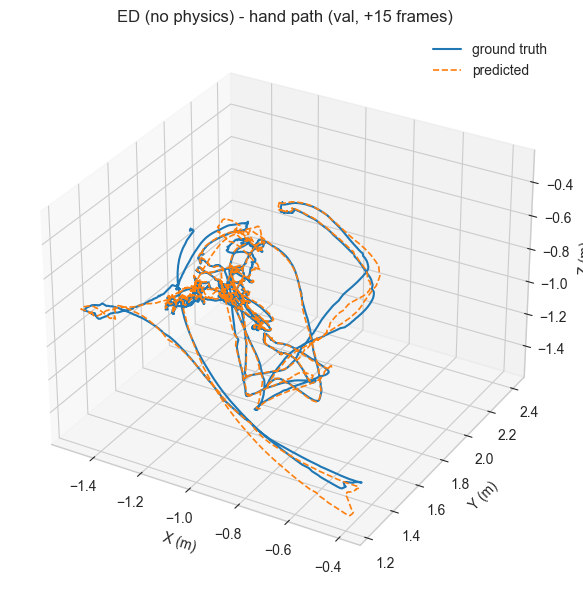

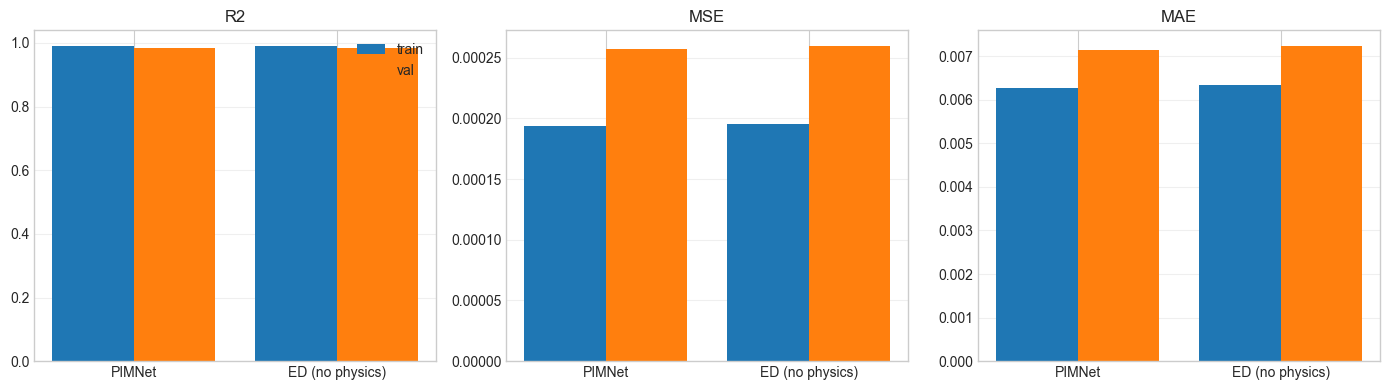


Saved 17 plots to ./pimnet_plots/


SystemExit: Edit the __main__ block (or import this module) to load your data.

C:\Users\Aini\AppData\Roaming\Python\Python314\site-packages\IPython\core\interactiveshell.py:3756: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [17]:
"""
PIMNet (Physics-infused Neural Network for Human Motion Prediction)
adapted to a 3-segment right-arm chain: RightArm -> RightForeArm -> RightHand.

Pipeline (follows Zhang et al., IEEE RA-L 2022):
  1. Convert Euler rotations -> quaternions (Eq. 15-17 analogue).
  2. Low-fidelity physics model: Newton-Euler inverse dynamics (Eq. 1-8)
        - segment kinematics via Savitzky-Golay differentiation (paper: forward differences)
        - gravity, anthropometric masses / inertias
        - optional hand-ground contact model (Eq. 4-6) + parameter optimisation (Eq. 9)
        - outputs joint torques (+ contact force) per frame  ->  X_p
  3. Physics-infused encoder (LSTM) + temporal decoder (LSTM)  (Eq. 11-13)
  4. L2 loss, Adam, lr 1e-3, 0.9 decay / 10k steps, batch 16   (Eq. 14, Sec. IV-B)
  5. Chronological 80/20 split, metrics: R2 / MSE / MAE for train and val
  6. Ablation: same encoder-decoder WITHOUT physics inputs (paper's "ED" curve)

Usage
-----
    from pimnet_arm import Config, run_pipeline, compare_with_ablation
    cfg = Config(fps=30, pos_scale=0.01, euler_order="ZXY", up_axis=1)
    table, runs = compare_with_ablation(pos_df, ros_df, cfg, return_runs=True)  # also saves graphs
    # or a single model:  res = run_pipeline(pos_df, ros_df, cfg, plot=True)
    # graphs only:        make_all_plots(runs, table, out_dir="pimnet_plots")
"""
from __future__ import annotations

import copy
import os
import random
from dataclasses import dataclass, field

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from scipy.optimize import minimize
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation as R
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import DataLoader, TensorDataset

# ----------------------------------------------------------------------------
# Column definitions (taken from your snippet)
# ----------------------------------------------------------------------------
JOINTS = ["RightArm", "RightForeArm", "RightHand"]
POS_COLS = [f"{j}_{a}position" for j in JOINTS for a in "XYZ"]
ROT_COLS = [f"{j}_{a}rotation" for j in JOINTS for a in "XYZ"]


# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
@dataclass
class Config:
    # ---- data / physics assumptions (CHECK THESE FOR YOUR DATA) ----
    fps: float = 30.0                 # sampling rate of your mocap data
    pos_scale: float = 0.01           # multiply positions by this to get metres (0.01 if cm)
    euler_order: str = "ZXY"          # BVH default is ZXY; use the order of your export
    degrees: bool = True              # rotations in degrees?
    rot_local: bool = True            # rotations are local (relative to parent), as in BVH
    up_axis: int = 1                  # 0=X, 1=Y, 2=Z is "up" (BVH: Y)
    body_mass: float = 70.0           # kg  (used for Dempster segment masses)
    seg_mass_ratio: tuple = (0.028, 0.016, 0.006)  # upper arm, forearm, hand
    hand_len_ratio: float = 0.7       # hand length as a fraction of forearm length
    seg_radius: float = 0.04          # m, for axial inertia
    sg_window: int = 9                # Savitzky-Golay window (odd)
    sg_poly: int = 3
    floor_height: float | None = None  # up-axis coordinate (m) of floor; None -> no contact
    optimize_contact: bool = True     # Eq. 9 (only runs if floor_height given)

    # ---- model / training ----
    t_in: int = 30                    # past frames fed to the encoder
    horizon: int = 15                 # future frames predicted
    stride: int = 1
    target: str = "both"              # "pos", "rot" (quaternion) or "both"
    hidden: int = 64                  # paper uses 1024; small data needs far less
    layers: int = 1
    dropout: float = 0.3              # applied to encoder state + decoder output
    weight_decay: float = 1e-3        # AdamW L2 regularisation
    input_noise: float = 0.03         # Gaussian noise (scaled units) added to inputs in training
    clip_pct: float = 1.0             # clip input features to [1%, 99%] range (tames torque spikes)
    predict_delta: bool = True        # predict change from last observed frame (big overfit fix)
    batch_size: int = 16
    lr: float = 1e-3
    decay_rate: float = 0.9
    decay_steps: int = 10_000
    epochs: int = 100
    patience: int = 15                # early stopping on val loss
    train_frac: float = 0.8
    seed: int = 42
    device: str = field(default_factory=lambda: "cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------
# 1. Rotations: Euler -> Rotation objects / quaternions
# ----------------------------------------------------------------------------
def euler_to_rotations(ros_arr: np.ndarray, cfg: Config):
    """ros_arr: (T, 9) in column order [X,Y,Z] per joint. Returns list of 3 Rotation objects."""
    T = ros_arr.shape[0]
    ang = ros_arr.reshape(T, 3, 3)
    idx = ["XYZ".index(c) for c in cfg.euler_order.upper()]
    return [R.from_euler(cfg.euler_order.upper(), ang[:, j, idx], degrees=cfg.degrees)
            for j in range(3)]


def quats_continuous(rots) -> np.ndarray:
    """(T, 3*4) quaternion features [x,y,z,w] with sign continuity (q and -q are the same rotation)."""
    out = []
    for r in rots:
        q = r.as_quat().copy()
        for t in range(1, len(q)):
            if np.dot(q[t], q[t - 1]) < 0:
                q[t] = -q[t]
        out.append(q)
    return np.concatenate(out, axis=1)


# ----------------------------------------------------------------------------
# 2. Physics model (low-fidelity Newton-Euler inverse dynamics)
# ----------------------------------------------------------------------------
def _sg(x, cfg: Config, deriv=0):
    w = min(cfg.sg_window, len(x) - (1 - len(x) % 2))
    w = w if w % 2 == 1 else w - 1
    return savgol_filter(x, w, min(cfg.sg_poly, w - 1), deriv=deriv, delta=1.0 / cfg.fps,
                         axis=0, mode="interp")


def _angular_velocity(Rg, dt):
    """World-frame angular velocity via central differences on rotations."""
    T = len(Rg)
    i = np.arange(T)
    nxt, prv = np.minimum(i + 1, T - 1), np.maximum(i - 1, 0)
    rel = Rg[nxt] * Rg[prv].inv()
    return rel.as_rotvec() / ((nxt - prv) * dt)[:, None]


def _inertia_mul(u, w, It, Ia):
    """I_world @ w for a rod with axis u:  I = It (1-uu^T) + Ia uu^T."""
    return It * w + (Ia - It) * u * np.sum(u * w, axis=-1, keepdims=True)


def compute_kinematics(pos_arr: np.ndarray, rots, cfg: Config) -> dict:
    """Segment COM acceleration, angular vel/acc, bone axes, hand-tip velocity."""
    dt = 1.0 / cfg.fps
    T = pos_arr.shape[0]
    P3 = pos_arr.reshape(T, 3, 3) * cfg.pos_scale          # shoulder, elbow, wrist
    tip = P3[:, 2] + cfg.hand_len_ratio * (P3[:, 2] - P3[:, 1])  # hand end-point
    P = np.stack([P3[:, 0], P3[:, 1], P3[:, 2], tip], axis=1)    # (T, 4, 3)
    P = np.stack([_sg(P[:, k], cfg, 0) for k in range(4)], axis=1)

    com = 0.5 * (P[:, :-1] + P[:, 1:])                       # (T, 3 segs, 3)
    a = np.stack([_sg(com[:, s], cfg, 2) for s in range(3)], axis=1)
    v_tip = _sg(P[:, 3], cfg, 1)

    # global segment orientations
    if cfg.rot_local:
        Rg = [rots[0], rots[0] * rots[1], rots[0] * rots[1] * rots[2]]
    else:
        Rg = rots
    omega, alpha = [], []
    for s in range(3):
        w = _sg(_angular_velocity(Rg[s], dt), cfg, 0)
        omega.append(w)
        alpha.append(_sg(w, cfg, 1))

    seg_vec = P[:, 1:] - P[:, :-1]                           # (T, 3, 3)
    L = np.linalg.norm(seg_vec, axis=-1)                     # (T, 3)
    u = seg_vec / (L[..., None] + 1e-9)
    return dict(P=P, com=com, a=a, v_tip=v_tip, omega=np.stack(omega, 1),
                alpha=np.stack(alpha, 1), u=u, L=L, Rg=Rg)


def contact_force(theta, kin, cfg: Config) -> np.ndarray:
    """Eq. (4)-(6): sigmoid-modulated spring-damper normal force + damper friction (hand tip)."""
    T = kin["P"].shape[0]
    if cfg.floor_height is None:
        return np.zeros((T, 3))
    k, cn, ct = theta
    S = lambda x: 0.5 * (1.0 + np.tanh(x))
    n = np.zeros(3)
    n[cfg.up_axis] = 1.0
    d = kin["P"][:, 3, cfg.up_axis] - cfg.floor_height       # distance to surface
    v = kin["v_tip"]
    vn = v @ n
    fn = -k * (d - 1.0) - cn * vn                            # Eq. 5 (as written in the paper)
    ft = -ct * (v - vn[:, None] * n[None])                   # Eq. 6
    gate = (S(-60.0 * d) * S(5.0 * fn))[:, None]
    return gate * (fn[:, None] * n[None] + ft)               # Eq. 4


def newton_euler(kin, f_contact, cfg: Config):
    """
    Recursive Newton-Euler from hand to shoulder (matrix form Eq. 1/7/8 solved per frame).
    Returns joint forces f (T,3,3) and joint torques tau (T,3,3) in the world frame.
    tau[:, s] is the torque the parent exerts on segment s at its proximal joint
    (shoulder, elbow, wrist) -> the "internal torque" tau of Eq. (8).
    """
    T = kin["P"].shape[0]
    g = np.zeros(3)
    g[cfg.up_axis] = -9.81
    P, com, a = kin["P"], kin["com"], kin["a"]
    f = np.zeros((T, 3, 3))
    tau = np.zeros((T, 3, 3))
    f_next = np.zeros((T, 3))
    tau_next = np.zeros((T, 3))
    for s in (2, 1, 0):
        m = cfg.body_mass * cfg.seg_mass_ratio[s]
        L = kin["L"][:, s:s + 1]
        It = m * L ** 2 / 12.0
        Ia = 0.5 * m * cfg.seg_radius ** 2
        u, w, al = kin["u"][:, s], kin["omega"][:, s], kin["alpha"][:, s]
        f_ext = f_contact if s == 2 else np.zeros((T, 3))
        r_prox = P[:, s] - com[:, s]
        r_dist = P[:, s + 1] - com[:, s]

        f[:, s] = m * (a[:, s] - g) + f_next - f_ext
        Iw = _inertia_mul(u, w, It, Ia)
        tau[:, s] = (_inertia_mul(u, al, It, Ia) + np.cross(w, Iw) + tau_next
                     - np.cross(r_prox, f[:, s]) + np.cross(r_dist, f_next)
                     - np.cross(r_dist, f_ext))
        f_next, tau_next = f[:, s], tau[:, s]
    return f, tau


def optimise_contact_params(kin, cfg: Config) -> np.ndarray:
    """Eq. (9): find theta=[k,cn,ct] minimising the root residual force (shoulder joint force)."""
    def cost(theta):
        fc = contact_force(theta, kin, cfg)
        f, _ = newton_euler(kin, fc, cfg)
        return float(np.mean(np.sum(f[:, 0] ** 2, axis=-1)))
    res = minimize(cost, x0=[10.0, 5.0, 5.0], method="L-BFGS-B",
                   bounds=[(1, 20), (0.1, 20), (0.1, 20)])
    return res.x


def physics_features(pos_arr, rots, cfg: Config):
    """Returns X_p (T, 12): 3 joint torques (segment frame) + 1 contact force, each 3-D."""
    kin = compute_kinematics(pos_arr, rots, cfg)
    theta = np.array([10.0, 5.0, 5.0])
    if cfg.floor_height is not None and cfg.optimize_contact:
        theta = optimise_contact_params(kin, cfg)
        print(f"[physics] optimised contact params k={theta[0]:.2f}, cn={theta[1]:.2f}, ct={theta[2]:.2f}")
    elif cfg.floor_height is None:
        print("[physics] floor_height=None -> contact forces set to zero (free-space arm motion).")
    fc = contact_force(theta, kin, cfg)
    _, tau = newton_euler(kin, fc, cfg)
    # express torques in each segment's own frame (muscle torques act in the joint frame)
    tau_loc = np.stack([kin["Rg"][s].inv().apply(tau[:, s]) for s in range(3)], axis=1)
    return np.concatenate([tau_loc.reshape(len(tau_loc), -1), fc], axis=1)


# ----------------------------------------------------------------------------
# 3. Data preparation
# ----------------------------------------------------------------------------
class MinMax11:
    """Per-feature scaling to [-1, 1] using (optionally clipped) percentiles."""
    def __init__(self, pct: float = 0.0, clip: bool = False):
        self.pct, self.clip = pct, clip

    def fit(self, x):
        self.lo = np.percentile(x, self.pct, axis=0)
        self.hi = np.percentile(x, 100 - self.pct, axis=0)
        return self

    def transform(self, x):
        z = 2 * (x - self.lo) / (self.hi - self.lo + 1e-8) - 1
        return np.clip(z, -2.0, 2.0) if self.clip else z

    def inverse(self, x):
        return (x + 1) / 2 * (self.hi - self.lo + 1e-8) + self.lo


def make_windows(F_in, F_out, t_in, horizon, stride):
    """Returns X (N,t_in,d_in), Y (N,horizon,d_out) and base (N,d_out) = last observed target frame."""
    n = len(F_in) - t_in - horizon + 1
    if n <= 0:
        raise ValueError("Not enough frames for the chosen t_in + horizon.")
    idx = np.arange(0, n, stride)
    X = np.stack([F_in[i:i + t_in] for i in idx]).astype(np.float32)
    Y = np.stack([F_out[i + t_in:i + t_in + horizon] for i in idx]).astype(np.float32)
    base = np.stack([F_out[i + t_in - 1] for i in idx]).astype(np.float32)
    return X, Y, base


def build_features(pos_df, ros_df, cfg: Config, use_physics: bool):
    pos_arr = pos_df[POS_COLS].to_numpy(dtype=float)
    ros_arr = ros_df[ROT_COLS].to_numpy(dtype=float)
    rots = euler_to_rotations(ros_arr, cfg)
    quat = quats_continuous(rots)
    pos_m = pos_arr * cfg.pos_scale
    parts = [pos_m, quat]
    if use_physics:
        parts.append(physics_features(pos_arr, rots, cfg))
    F_in = np.concatenate(parts, axis=1)
    F_out = {"pos": pos_m, "rot": quat, "both": np.concatenate([pos_m, quat], axis=1)}[cfg.target]
    return F_in, F_out


# ----------------------------------------------------------------------------
# 4. Model: physics-infused encoder + temporal decoder
# ----------------------------------------------------------------------------
class PIMNet(nn.Module):
    def __init__(self, d_in, d_out, hidden, layers, horizon, dropout=0.0):
        super().__init__()
        dp = dropout if layers > 1 else 0.0
        self.horizon = horizon
        self.encoder = nn.LSTM(d_in, hidden, layers, batch_first=True, dropout=dp)   # Eq. 11
        self.decoder = nn.LSTM(hidden, hidden, layers, batch_first=True, dropout=dp)  # Eq. 12
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(hidden, d_out)

    def forward(self, x):                       # x: (B, T_in, d_in)  = [X_i, X_p]
        _, (h, _) = self.encoder(x)
        ctx = self.drop(h[-1]).unsqueeze(1).repeat(1, self.horizon, 1)  # encoder state -> decoder
        y, _ = self.decoder(ctx)
        return self.out(self.drop(y))           # (B, L, d_out)


@torch.no_grad()
def predict(model, X, device, bs=256):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(X[i:i + bs]).to(device)).cpu().numpy())
    return np.concatenate(out)


def train_model(model, Xtr, Ytr, Xva, Yva, cfg: Config):
    dev = cfg.device
    model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    # paper: 0.9 decay / 10k steps (does almost nothing on small data) -> plateau-based decay instead
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    loss_fn = nn.MSELoss()                                       # l2 loss, Eq. 14
    dl = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(Ytr)),
                    batch_size=cfg.batch_size, shuffle=True)
    best, best_state, bad = np.inf, None, 0
    hist = {"train": [], "val": []}
    for ep in range(1, cfg.epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(dev), yb.to(dev)
            if cfg.input_noise > 0:
                xb = xb + cfg.input_noise * torch.randn_like(xb)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(xb)
            n += len(xb)
        va = float(np.mean((predict(model, Xva, dev) - Yva) ** 2))
        sched.step(va)
        hist["train"].append(tot / n)
        hist["val"].append(va)
        if ep == 1 or ep % 5 == 0:
            print(f"epoch {ep:3d} | train {tot / n:.5f} | val {va:.5f} | lr {opt.param_groups[0]['lr']:.1e}")
        if va < best - 1e-7:
            best, best_state, bad = va, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= cfg.patience:
                print(f"early stopping at epoch {ep} (best val {best:.5f})")
                break
    model.load_state_dict(best_state)
    return model, hist


# ----------------------------------------------------------------------------
# 5. Evaluation
# ----------------------------------------------------------------------------
def regression_metrics(Y_true, Y_pred, scaler: MinMax11) -> dict:
    """Metrics on the ORIGINAL scale (metres / quaternion units); flattened over samples x horizon."""
    d = Y_true.shape[-1]
    yt = scaler.inverse(Y_true.reshape(-1, d))
    yp = scaler.inverse(Y_pred.reshape(-1, d))
    return {"R2": r2_score(yt, yp), "MSE": mean_squared_error(yt, yp),
            "MAE": mean_absolute_error(yt, yp)}


def run_pipeline(pos_df: pd.DataFrame, ros_df: pd.DataFrame, cfg: Config | None = None,
                 use_physics: bool = True, plot: bool = False,
                 out_dir: str = "pimnet_plots", show: bool = True) -> dict:
    cfg = cfg or Config()
    set_seed(cfg.seed)
    tag = "PIMNet (physics-infused)" if use_physics else "ED ablation (no physics)"
    print(f"\n===== {tag} | device={cfg.device} =====")

    F_in, F_out = build_features(pos_df, ros_df, cfg, use_physics)

    # chronological 80/20 split on the raw sequence -> no window overlap / leakage
    cut = int(len(F_in) * cfg.train_frac)
    sc_in = MinMax11(cfg.clip_pct, clip=True).fit(F_in[:cut])   # fit on TRAIN only
    sc_out = MinMax11().fit(F_out[:cut])
    A, B = sc_in.transform(F_in), sc_out.transform(F_out)
    Xtr, Ytr, Btr = make_windows(A[:cut], B[:cut], cfg.t_in, cfg.horizon, cfg.stride)
    Xva, Yva, Bva = make_windows(A[cut:], B[cut:], cfg.t_in, cfg.horizon, cfg.stride)
    print(f"train windows: {len(Xtr)} | val windows: {len(Xva)} | "
          f"input dim: {Xtr.shape[-1]} | output dim: {Ytr.shape[-1]}")

    # train on residuals w.r.t. the last observed frame (much easier than absolute targets)
    Ttr = Ytr - Btr[:, None] if cfg.predict_delta else Ytr
    Tva = Yva - Bva[:, None] if cfg.predict_delta else Yva

    model = PIMNet(Xtr.shape[-1], Ytr.shape[-1], cfg.hidden, cfg.layers, cfg.horizon, cfg.dropout)
    model, hist = train_model(model, Xtr, Ttr, Xva, Tva, cfg)

    def full_pred(X, base):
        d = predict(model, X, cfg.device)
        return d + base[:, None] if cfg.predict_delta else d

    m_tr = regression_metrics(Ytr, full_pred(Xtr, Btr), sc_out)
    m_va = regression_metrics(Yva, full_pred(Xva, Bva), sc_out)
    base_va = regression_metrics(Yva, np.repeat(Bva[:, None], cfg.horizon, 1), sc_out)
    print(f"\n{tag}")
    print(f"  TRAIN: R2={m_tr['R2']:.4f}  MSE={m_tr['MSE']:.6f}  MAE={m_tr['MAE']:.6f}")
    print(f"  VAL  : R2={m_va['R2']:.4f}  MSE={m_va['MSE']:.6f}  MAE={m_va['MAE']:.6f}")
    print(f"  VAL baseline (repeat last frame): R2={base_va['R2']:.4f}  "
          f"MSE={base_va['MSE']:.6f}  MAE={base_va['MAE']:.6f}")
    # predictions in ORIGINAL units, kept for plotting
    def inv(Y):
        return sc_out.inverse(Y.reshape(-1, Y.shape[-1])).reshape(Y.shape)
    pred = dict(yt_tr=inv(Ytr), yp_tr=inv(full_pred(Xtr, Btr)),
                yt_va=inv(Yva), yp_va=inv(full_pred(Xva, Bva)),
                yp_base_va=inv(np.repeat(Bva[:, None], cfg.horizon, 1)))
    res = {"model": model, "history": hist, "train": m_tr, "val": m_va, "baseline_val": base_va,
           "scalers": (sc_in, sc_out), "cfg": cfg, "pred": pred, "names": target_names(cfg),
           "cut": cut, "F_in": F_in, "use_physics": use_physics, "tag": tag}
    if plot:
        make_all_plots({tag: res}, out_dir=out_dir, show=show)
    return res


# ----------------------------------------------------------------------------
# 6. Graphs
# ----------------------------------------------------------------------------
def target_names(cfg: Config):
    q = [f"{j}_q{c}" for j in JOINTS for c in "xyzw"]
    return {"pos": list(POS_COLS), "rot": q, "both": list(POS_COLS) + q}[cfg.target]


def _slug(s):
    return "".join(c if c.isalnum() else "_" for c in s).strip("_").lower()


def _finish(fig, out_dir, fname, show):
    fig.tight_layout()
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, fname)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)
    return path


def _default_features(names):
    hand = [f"RightHand_{a}position" for a in "XYZ"]
    f = [n for n in hand if n in names]
    return f if f else names[:3]


def plot_loss(runs, out_dir, show=True):
    """Training vs validation loss (scaled MSE) for every run; dotted line = best-val epoch."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for name, r in runs.items():
        h = r["history"]
        (ln,) = ax.plot(h["train"], label=f"{name} - train")
        ax.plot(h["val"], "--", color=ln.get_color(), label=f"{name} - val")
        ax.axvline(int(np.argmin(h["val"])), color=ln.get_color(), ls=":", alpha=0.4)
    ax.set_yscale("log")
    ax.set(xlabel="epoch", ylabel="MSE (scaled units)", title="Training vs validation loss")
    ax.legend()
    ax.grid(alpha=0.3)
    return _finish(fig, out_dir, "loss_curves.png", show)


def plot_pred_vs_gt(res, split="val", steps=(0, -1), features=None, out_dir="pimnet_plots", show=True):
    """Predicted vs ground-truth time series. Column = how many frames ahead is being predicted."""
    cfg, names = res["cfg"], res["names"]
    features = features or _default_features(names)
    k = "va" if split == "val" else "tr"
    yt, yp = res["pred"][f"yt_{k}"], res["pred"][f"yp_{k}"]
    N, H, _ = yt.shape
    fig, axes = plt.subplots(len(features), len(steps), figsize=(6 * len(steps), 2.6 * len(features)),
                             squeeze=False, sharex="col")
    for c, h in enumerate(steps):
        h = h % H
        off = cfg.t_in + h + (res["cut"] if split == "val" else 0)
        t = (off + np.arange(N) * cfg.stride) / cfg.fps
        for r, fn in enumerate(features):
            f = names.index(fn)
            ax = axes[r, c]
            ax.plot(t, yt[:, h, f], label="ground truth", lw=1.4)
            ax.plot(t, yp[:, h, f], "--", label="predicted", lw=1.2)
            ax.set_ylabel(fn.replace("_", "\n", 1), fontsize=8)
            ax.grid(alpha=0.3)
            if r == 0:
                ax.set_title(f"{split}: +{h + 1} frame(s) ahead ({(h + 1) / cfg.fps:.2f}s)")
            if r == 0 and c == 0:
                ax.legend(fontsize=8)
        axes[-1, c].set_xlabel("time (s)")
    fig.suptitle(f"{res['tag']} - predicted vs ground truth ({split})", y=1.0)
    return _finish(fig, out_dir, f"{_slug(res['tag'])}_pred_vs_gt_{split}.png", show)


def plot_scatter(res, features=None, out_dir="pimnet_plots", show=True, max_pts=5000):
    """Predicted-vs-actual scatter (train row, val row) with per-feature R2; ideal = diagonal."""
    names = res["names"]
    features = features or _default_features(names)
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(2, len(features), figsize=(4.2 * len(features), 8), squeeze=False)
    for r, (k, lab) in enumerate([("tr", "train"), ("va", "val")]):
        yt, yp = res["pred"][f"yt_{k}"], res["pred"][f"yp_{k}"]
        for c, fn in enumerate(features):
            f = names.index(fn)
            a, b = yt[:, :, f].ravel(), yp[:, :, f].ravel()
            i = rng.choice(len(a), min(max_pts, len(a)), replace=False)
            ax = axes[r, c]
            ax.scatter(a[i], b[i], s=5, alpha=0.35)
            lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
            ax.plot([lo, hi], [lo, hi], "r--", lw=1)
            ax.set(xlabel="ground truth", ylabel="predicted", title=f"{lab}: {fn}")
            ax.text(0.05, 0.92, f"R2 = {r2_score(a, b):.3f}", transform=ax.transAxes)
            ax.grid(alpha=0.3)
    fig.suptitle(f"{res['tag']} - predicted vs actual", y=1.0)
    return _finish(fig, out_dir, f"{_slug(res['tag'])}_scatter.png", show)


def plot_horizon_metrics(res, out_dir="pimnet_plots", show=True):
    """R2 / MAE / MSE as a function of prediction horizon (train, val, and repeat-last-frame baseline)."""
    cfg, P = res["cfg"], res["pred"]
    H = P["yt_va"].shape[1]
    t = (np.arange(H) + 1) / cfg.fps
    series = {"train": (P["yt_tr"], P["yp_tr"]), "val": (P["yt_va"], P["yp_va"]),
              "val baseline (last frame)": (P["yt_va"], P["yp_base_va"])}
    fns = {"R2": lambda a, b: r2_score(a, b),
           "MAE": lambda a, b: mean_absolute_error(a, b),
           "MSE": lambda a, b: mean_squared_error(a, b)}
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (m, fn) in zip(axes, fns.items()):
        for lab, (yt, yp) in series.items():
            ax.plot(t, [fn(yt[:, h], yp[:, h]) for h in range(H)], marker="o", ms=3,
                    ls=":" if "baseline" in lab else "-", label=lab)
        ax.set(xlabel="prediction horizon (s)", ylabel=m, title=f"{m} vs horizon")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(res["tag"], y=1.02)
    return _finish(fig, out_dir, f"{_slug(res['tag'])}_horizon_metrics.png", show)


def plot_samples(res, n=4, features=None, out_dir="pimnet_plots", show=True):
    """Individual validation windows: ground-truth future vs predicted future vs last-frame baseline."""
    names, cfg = res["names"], res["cfg"]
    features = features or _default_features(names)
    P = res["pred"]
    N, H, _ = P["yt_va"].shape
    idx = np.linspace(0, N - 1, n).astype(int)
    t = (np.arange(H) + 1) / cfg.fps
    fig, axes = plt.subplots(n, len(features), figsize=(4.5 * len(features), 2.4 * n), squeeze=False)
    for r, i in enumerate(idx):
        for c, fn in enumerate(features):
            f = names.index(fn)
            ax = axes[r, c]
            ax.plot(t, P["yt_va"][i, :, f], "o-", ms=3, label="ground truth")
            ax.plot(t, P["yp_va"][i, :, f], "s--", ms=3, label="predicted")
            ax.plot(t, P["yp_base_va"][i, :, f], ":", color="gray", label="last-frame baseline")
            ax.grid(alpha=0.3)
            if r == 0:
                ax.set_title(fn, fontsize=9)
            if c == 0:
                ax.set_ylabel(f"window {i}", fontsize=8)
            if r == 0 and c == 0:
                ax.legend(fontsize=7)
        axes[-1, 0].set_xlabel("future time (s)")
    fig.suptitle(f"{res['tag']} - validation windows", y=1.0)
    return _finish(fig, out_dir, f"{_slug(res['tag'])}_samples.png", show)


def plot_residuals(res, out_dir="pimnet_plots", show=True):
    """Histogram of standardised residuals (error / std of that feature) for train and val."""
    P = res["pred"]
    fig, ax = plt.subplots(figsize=(7, 4))
    for k, lab in [("tr", "train"), ("va", "val")]:
        yt, yp = P[f"yt_{k}"], P[f"yp_{k}"]
        sd = yt.reshape(-1, yt.shape[-1]).std(0) + 1e-9
        ax.hist(((yp - yt) / sd).ravel(), bins=80, alpha=0.5, density=True, label=lab)
    ax.axvline(0, color="k", lw=0.8)
    ax.set(xlabel="(predicted - truth) / feature std", ylabel="density",
           title=f"{res['tag']} - residual distribution")
    ax.legend()
    return _finish(fig, out_dir, f"{_slug(res['tag'])}_residuals.png", show)


def plot_physics(res, out_dir="pimnet_plots", show=True):
    """Physics-model outputs over time: joint torque magnitudes and contact force magnitude."""
    if not res["use_physics"]:
        return None
    cfg = res["cfg"]
    F = res["F_in"][:, -12:]
    T = len(F)
    tau = np.linalg.norm(F[:, :9].reshape(T, 3, 3), axis=-1)
    fc = np.linalg.norm(F[:, 9:12], axis=-1)
    t = np.arange(T) / cfg.fps
    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    for j, nm in enumerate(["Shoulder (RightArm)", "Elbow (RightForeArm)", "Wrist (RightHand)"]):
        axes[j].plot(t, tau[:, j])
        axes[j].set_ylabel(f"|torque| N·m\n{nm}", fontsize=8)
    axes[3].plot(t, fc)
    axes[3].set_ylabel("|contact force| N", fontsize=8)
    for ax in axes:
        ax.axvline(res["cut"] / cfg.fps, color="r", ls="--", alpha=0.6)
        ax.grid(alpha=0.3)
    axes[0].text(res["cut"] / cfg.fps, axes[0].get_ylim()[1], " val →", color="r", va="top")
    axes[-1].set_xlabel("time (s)")
    fig.suptitle("Physics-model features (inverse dynamics)", y=1.0)
    return _finish(fig, out_dir, f"{_slug(res['tag'])}_physics_features.png", show)


def plot_hand_3d(res, step=-1, out_dir="pimnet_plots", show=True):
    """3-D right-hand trajectory: ground truth vs predicted (validation set)."""
    names = res["names"]
    hand = [f"RightHand_{a}position" for a in "XYZ"]
    if not all(n in names for n in hand):
        return None
    idx = [names.index(n) for n in hand]
    P = res["pred"]
    h = step % P["yt_va"].shape[1]
    gt, pr = P["yt_va"][:, h][:, idx], P["yp_va"][:, h][:, idx]
    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(projection="3d")
    ax.plot(*gt.T, label="ground truth", lw=1.5)
    ax.plot(*pr.T, "--", label="predicted", lw=1.2)
    ax.set(xlabel="X (m)", ylabel="Y (m)", zlabel="Z (m)",
           title=f"{res['tag']} - hand path (val, +{h + 1} frames)")
    ax.legend()
    return _finish(fig, out_dir, f"{_slug(res['tag'])}_hand_3d.png", show)


def plot_comparison(table, out_dir="pimnet_plots", show=True):
    """Bar chart: train vs val R2 / MSE / MAE for PIMNet vs the no-physics ablation."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    x = np.arange(len(table))
    for ax, m in zip(axes, ["R2", "MSE", "MAE"]):
        ax.bar(x - 0.2, table[f"{m}_train"], 0.4, label="train")
        ax.bar(x + 0.2, table[f"{m}_val"], 0.4, label="val")
        ax.set_xticks(x)
        ax.set_xticklabels(table.index)
        ax.set_title(m)
        ax.grid(alpha=0.3, axis="y")
    axes[0].legend()
    return _finish(fig, out_dir, "comparison_bars.png", show)


def make_all_plots(runs: dict, table: pd.DataFrame | None = None,
                   out_dir: str = "pimnet_plots", show: bool = True) -> list:
    """runs: {name: result-dict from run_pipeline}. Saves every graph to out_dir as PNG."""
    paths = [plot_loss(runs, out_dir, show)]
    for res in runs.values():
        paths += [plot_pred_vs_gt(res, "val", out_dir=out_dir, show=show),
                  plot_pred_vs_gt(res, "train", out_dir=out_dir, show=show),
                  plot_scatter(res, out_dir=out_dir, show=show),
                  plot_horizon_metrics(res, out_dir=out_dir, show=show),
                  plot_samples(res, out_dir=out_dir, show=show),
                  plot_residuals(res, out_dir=out_dir, show=show),
                  plot_physics(res, out_dir=out_dir, show=show),
                  plot_hand_3d(res, out_dir=out_dir, show=show)]
    if table is not None:
        paths.append(plot_comparison(table, out_dir, show))
    paths = [p for p in paths if p]
    print(f"\nSaved {len(paths)} plots to ./{out_dir}/")
    return paths


def compare_with_ablation(pos_df, ros_df, cfg: Config | None = None, plot: bool = True,
                          out_dir: str = "pimnet_plots", show: bool = True, return_runs: bool = False):
    """Runs PIMNet and the physics-free ED ablation, prints a table and (optionally) saves all graphs."""
    cfg = cfg or Config()
    rows, runs = {}, {}
    for name, flag in [("PIMNet", True), ("ED (no physics)", False)]:
        r = run_pipeline(pos_df, ros_df, cfg, use_physics=flag)
        r["tag"] = name
        runs[name] = r
        rows[name] = {"R2_train": r["train"]["R2"], "R2_val": r["val"]["R2"],
                      "MSE_train": r["train"]["MSE"], "MSE_val": r["val"]["MSE"],
                      "MAE_train": r["train"]["MAE"], "MAE_val": r["val"]["MAE"]}
    table = pd.DataFrame(rows).T
    print("\n" + table.to_string(float_format=lambda x: f"{x:.5f}"))
    if plot:
        make_all_plots(runs, table, out_dir=out_dir, show=show)
    return (table, runs) if return_runs else table


if __name__ == "__main__":
    # ---- replace with your own data loading ----
    # position = pd.read_csv("position.csv"); rotation = pd.read_csv("rotation.csv")
    # pos_df = position[POS_COLS]; ros_df = rotation[ROT_COLS]
    cfg = Config(fps=30, pos_scale=0.01, euler_order="ZXY", up_axis=1)
    compare_with_ablation(pos_df, ros_df, cfg)
    raise SystemExit("Edit the __main__ block (or import this module) to load your data.")